# Lab 3, Notebook A — The Gaussian, computed

*Linear Algebra for Data Science, UCU 2026. Uses Session 4.1 (spectral theorem, Cholesky, matrix square root) and Session 4.2 (covariance, whitening, Mahalanobis distance, the Gaussian density).*

The multivariate normal density needs $\Sigma^{-1}$ and $\det\Sigma$, whitening needs a square root of $\Sigma$, and sampling needs any factor $B$ with $BB^\top = \Sigma$. In this notebook you will compute all of them from **one Cholesky factorization** $\Sigma = LL^\top$, never forming an inverse or a determinant. You will also see each of them fail when the matrix is nearly singular.

**How to work.** Most tasks ask you to **predict first, in writing, then compute, then explain any difference**. Write the prediction *before* running the cell. A wrong prediction with an honest explanation earns more at the defence than a correct number you cannot explain.

**Rules.**
- Inside the functions you implement, do not call `np.linalg.inv`, `np.linalg.det` or `scipy.stats.multivariate_normal`. Use them only where a cell says **check** (and in `gauss_logpdf_naive`, which exists to be compared).
- You may use `scipy.linalg.cholesky`, `solve_triangular`, `cho_factor`/`cho_solve` and `np.linalg.eigh`.
- Do not change the seeds.
- Before you submit, run `Kernel → Restart & Run All`.

**Marking.** Core A is worth 2 points at the defence; the code point and the extension are shared with Notebook B.

**Contents.** A1 Covariance and whitening · A2 `log det` without `det` · A3 Sampling · Extensions E1 (repairing a correlation matrix) and E2 (Fisher's discriminant). Attempt **at most one** extension in the whole lab.

| | |
|---|---|
| **Team member 1** | *Vladyslav Hryhola* |
| **Team member 2** | *Ihor Kashuba* |
| **Extension attempted** (at most one in the whole lab) | E3 in Core B |
| **Late days used on this lab** | *0* |
| **Runs top to bottom from a clean kernel** | *yes* |

In [1]:
import sys, time
import numpy as np
import scipy, scipy.linalg as sl
import pandas as pd
import matplotlib, matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_breast_cancer, load_wine

print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__, "| sklearn", sklearn.__version__)
np.set_printoptions(precision=4, suppress=False, linewidth=110)

python 3.14.6 | numpy 2.5.3 | scipy 1.18.1 | pandas 3.0.6 | matplotlib 3.11.2 | sklearn 1.9.1


---
## A1. Covariance and whitening

The data set has 569 breast tumours and 30 features of the cell nuclei (radius, texture, area, smoothness, ...), measured in very different units. Rows are observations, columns are features.

In [2]:
data = load_breast_cancer()
X = data.data
n, p = X.shape
print(n, "tumours,", p, "features; first five:", list(data.feature_names[:5]))

569 tumours, 30 features; first five: [np.str_('mean radius'), np.str_('mean texture'), np.str_('mean perimeter'), np.str_('mean area'), np.str_('mean smoothness')]


**(a)** Implement `sample_cov(X)`, the sample covariance $\operatorname{Cov} = \frac1n X_c^\top X_c$ of the centred data. The course uses the divisor $1/n$, so do not use `np.cov`, which divides by $n-1$. Then implement `sample_corr(X)`, the sample correlation matrix.

In [3]:
def sample_cov(X):
    # YOUR CODE HERE
    x_mean = X.mean(axis=0)  # axis=0 averages down the rows: one mean for each feature
    Xc = X - x_mean  # centred observations, stored as rows (X_c in the formula)
    n = X.shape[0]  # number of observations
    C = Xc.T @ Xc / n  # Cov = (1/n) X_c^T X_c, with the course divisor 1/n
    return C

def sample_corr(X):
    # YOUR CODE HERE
    x_mean = X.mean(axis=0)  # one mean for each feature
    sigma = X.std(axis=0)  # one standard deviation for each feature, same divisor n as sample_cov
    Xs = (X - x_mean) / sigma  # standardised observations: zero mean and unit variance in every column
    R = sample_cov(Xs)  # correlation matrix = covariance of the standardised data
    return R

In [4]:
# check
C, R = sample_cov(X), sample_corr(X)
assert np.allclose(C, np.cov(X, rowvar=False, bias=True))
assert np.allclose(R, np.corrcoef(X, rowvar=False))
for name, M in [("Cov", C), ("Corr", R)]:
    ev = np.linalg.eigvalsh(M)
    print(f"{name}: symmetric {np.allclose(M, M.T)}, eigenvalues in [{ev[0]:.3e}, {ev[-1]:.3e}]")

Cov: symmetric True, eigenvalues in [7.008e-07, 4.430e+05]
Corr: symmetric True, eigenvalues in [1.330e-04, 1.328e+01]


**(b)** *Predict, then compute.* Which of `Cov` and `Corr` do you expect to be worse conditioned, and why? Write your prediction, then compute both condition numbers from the eigenvalues. What does the difference tell you about the units of the features?

**Your prediction** *(write it before running the next cell)*:

I expect the covariance matrix to be worse conditioned, because the features have very different units and scales. The correlation matrix is the covariance of standardised features, so its condition number should be much smaller.


In [5]:
def cond_sym(M):
    ev = np.linalg.eigvalsh(M)
    return ev[-1] / ev[0]

# YOUR CODE HERE
cond_C = cond_sym(C)
cond_R = cond_sym(R)
print(f"cond(Cov) = {cond_C:.3e}")
print(f"cond(Corr) = {cond_R:.3e}")
print(f"cond(Cov) / cond(Corr) = {cond_C / cond_R:.3e}")

cond(Cov) = 6.322e+11
cond(Corr) = 9.983e+04
cond(Cov) / cond(Corr) = 6.333e+06


**Your answer.** The covariance matrix has condition number about 632 billion ($6.3 \times 10^{11}$); the correlation matrix about 100 thousand ($10^{5}$), roughly 6 million times smaller. This agrees with my prediction. Most of the bad conditioning comes from the units: standardising removes it, although the correlation matrix is still far from well conditioned.

**(c)** Implement three whitening maps. Each takes the data `X` and returns the whitened centred data `W` ($n\times p$), whose sample covariance should be the identity:

| function | map | factorization |
|---|---|---|
| `whiten_chol(X)` | $A = L^{-1}$ | $\operatorname{Cov} = LL^\top$ |
| `whiten_pca(X)` | $A = D^{-1/2}U^\top$ | $\operatorname{Cov} = UDU^\top$ |
| `whiten_zca(X)` | $A = \operatorname{Cov}^{-1/2}$ | symmetric square root |

Apply the map with solves and products, never with an inverse. Rows of `W` are $A(\mathbf{x}_i - \bar{\mathbf{x}})$.

In [6]:
def whiten_chol(X):
    # YOUR CODE HERE
    x_mean = X.mean(axis=0)  # one mean for each feature
    Xc = X - x_mean  # centred observations, stored as rows
    C = sample_cov(X)  # covariance matrix of the features
    L = sl.cholesky(C, lower=True)  # lower triangular factor: C = L @ L.T

    Xc_columns = Xc.T  # put observations into columns for the solve
    W_columns = sl.solve_triangular(L, Xc_columns, lower=True)  # solve L @ W_columns = Xc_columns, i.e. apply A = L^(-1)
    W = W_columns.T  # put whitened observations back into rows
    return W

def whiten_pca(X):
    # YOUR CODE HERE
    x_mean = X.mean(axis=0)  # one mean for each feature
    Xc = X - x_mean  # centred observations, stored as rows
    C = sample_cov(X)  # covariance matrix of the features
    d, U = np.linalg.eigh(C)  # eigenvalues d (the diagonal of D) and eigenvectors U: C = U @ diag(d) @ U.T

    Xc_U = Xc @ U  # observations in the eigenvector directions (principal coordinates)
    sqrt_d = np.sqrt(d)  # standard deviation along each principal direction, sqrt of D
    W = Xc_U / sqrt_d  # divide each column by its standard deviation: rows are D^(-1/2) U^T (x_i - x_mean)
    return W

def whiten_zca(X):
    # YOUR CODE HERE
    x_mean = X.mean(axis=0)  # one mean for each feature
    Xc = X - x_mean  # centred original observations
    C = sample_cov(X)  # covariance of the original features
    d, U = np.linalg.eigh(C)  # eigenvalues d and eigenvectors U: C = U @ diag(d) @ U.T
    Xc_U = Xc @ U  # observations in the eigenvector directions
    sqrt_d = np.sqrt(d)  # standard deviations in those directions
    W_pca = Xc_U / sqrt_d  # whitened observations in the PCA directions
    W = W_pca @ U.T  # rotate back to the original axes: equals Xc @ Cov^(-1/2), since Cov^(-1/2) = U @ diag(1/sqrt_d) @ U.T
    return W

In [7]:
# check: the sample covariance of each whitened data set is I, to rounding error
whiteners = {"Cholesky": whiten_chol, "PCA": whiten_pca, "ZCA": whiten_zca}
for name, f in whiteners.items():
    W = f(X)
    err = np.abs(sample_cov(W) - np.eye(p)).max()
    print(f"{name:8s} max |Cov(W) - I| = {err:.1e}")
    assert err < 1e-6

Cholesky max |Cov(W) - I| = 1.6e-12
PCA      max |Cov(W) - I| = 3.3e-09
ZCA      max |Cov(W) - I| = 6.2e-09


*Question.* The three errors above are all small, but they differ by several orders of magnitude. Which map is most accurate here, and why might the two that use `eigh` lose more digits on this matrix? (Look back at (b).)

**Your answer.** Cholesky is the most accurate: error about 2 trillionths ($2 \times 10^{-12}$) against about 3 billionths ($3 \times 10^{-9}$) for PCA and 6 billionths ($6 \times 10^{-9}$) for ZCA. The condition number from (b) is about 630 billion, so the smallest eigenvalues are tiny compared with the largest. `eigh` computes them with a rounding error that is small next to the largest eigenvalue but not next to the smallest, and PCA and ZCA then divide by the square roots of those eigenvalues, which magnifies the error. Cholesky works on the matrix entries directly and never divides by a tiny eigenvalue.

**(d)** For each whitening compute the mean squared displacement $\frac1n\sum_i \|\mathbf{w}_i - (\mathbf{x}_i-\bar{\mathbf{x}})\|^2$. Which is smallest? State the theorem from Session 4.2 that predicts this.

The data are in very different units, so the displacement is dominated by the large-scale features. Repeat on the **standardised** data (each column centred and divided by its standard deviation). Does the ranking change? Do the differences become easier to see?

In [8]:
def msd(W, X):
    # YOUR CODE HERE
    x_mean = X.mean(axis=0)  # original feature means
    Xc = X - x_mean  # centred original observations
    differences = W - Xc  # movement of each coordinate during whitening
    squared_distances = np.sum(differences ** 2, axis=1)  # squared movement per observation
    mean_squared_displacement = squared_distances.mean()  # average squared movement per observation
    return mean_squared_displacement

Xs = (X - X.mean(axis=0)) / X.std(axis=0)      # standardised data, used again below
for label, Z in [("raw", X), ("standardised", Xs)]:
    print(label, {name: round(float(msd(f(Z), Z)), 3) for name, f in whiteners.items()})

raw {'Cholesky': 450904.689, 'PCA': 451132.373, 'ZCA': 449540.137}
standardised {'Cholesky': 36.12, 'PCA': 59.788, 'ZCA': 22.686}


**Your answer.** ZCA moves the data least, for both raw and standardised data: ZCA < Cholesky < PCA. Raw: about 449.5, 450.9 and 451.1 thousand; standardised: 22.7, 36.1 and 59.8. The symmetric (ZCA) whitening theorem from Session 4.2 predicts this: for a positive definite covariance, $\operatorname{Cov}^{-1/2}$ is the whitening map with the smallest mean squared displacement. In raw units the large-scale features dominate and the three numbers differ by less than 1%; after standardising, the differences are easy to see.

**(e)** The **Mahalanobis distance** of $\mathbf{x}$ from the mean is $d(\mathbf{x}) = \sqrt{(\mathbf{x}-\bar{\mathbf{x}})^\top\operatorname{Cov}^{-1}(\mathbf{x}-\bar{\mathbf{x}})}$.

1. Compute it for every tumour in three ways: as the Euclidean norm of the rows of each of the three whitened data sets from (c). Show that the three agree to rounding error, and explain in two sentences why they must, using $A^\top A$.
2. Implement `mahalanobis(x, mu, L)` for **one** new point, given the mean and the Cholesky factor $L$ of `Cov`. Use one triangular solve, so the cost is $O(p^2)$ per point. Check it against part 1 on all tumours, and list the five tumours with the largest distance.

In [9]:
# YOUR CODE HERE
distances = {}  # one distance array for each whitening method
for name, f in whiteners.items():
    W = f(X)  # whitened observations for this method
    distances[name] = np.linalg.norm(W, axis=1)  # Euclidean distance of each row from zero

reference = distances["Cholesky"]  # distances used for comparison
for name, values in distances.items():
    difference = np.max(np.abs(values - reference))  # largest disagreement across tumours
    print(f"{name:8s} max distance difference = {difference:.3e}")
    assert np.allclose(values, reference)


Cholesky max distance difference = 0.000e+00
PCA      max distance difference = 1.953e-08
ZCA      max distance difference = 1.953e-08


**Your answer.** All three whitenings satisfy $A^\top A = \operatorname{Cov}^{-1}$, so $\|A(x-\bar{x})\|^2 = (x-\bar{x})^\top \operatorname{Cov}^{-1}(x-\bar{x})$ for each of them. The three distance vectors therefore agree exactly in theory and to about 20 billionths ($2 \times 10^{-8}$) in practice. The one-point version solves $Lw = x - \bar{x}$ once and returns $\|w\|$: one triangular solve, $O(p^2)$ per point. The five most unusual tumours are rows 152, 212, 461, 12 and 68 (zero-based), at distances 20.2, 19.6, 17.4, 14.6 and 14.3.

In [10]:
def mahalanobis(x, mu, L):
    # YOUR CODE HERE
    xc = x - mu  # x - mu: the point relative to the mean, like one row of Xc
    w = sl.solve_triangular(L, xc, lower=True)  # solve L @ w = x - mu, the whitened displacement
    distance = np.linalg.norm(w)  # Euclidean length of w = Mahalanobis distance
    return distance

mu, L = X.mean(axis=0), sl.cholesky(sample_cov(X), lower=True)
d_one = np.array([mahalanobis(x, mu, L) for x in X])
# check
assert np.allclose(d_one, np.linalg.norm(whiten_chol(X), axis=1))
top5 = np.argsort(d_one)[::-1][:5]
print("five most outlying tumours:", top5, "distances", np.round(d_one[top5], 2))

five most outlying tumours: [152 212 461  12  68] distances [20.21 19.63 17.35 14.6  14.28]


**(f)** *When $p$ approaches $n$.* Draw random subsamples of $m$ rows for $m = 500, 100, 50, 35, 31, 30, 25$, and for each compute the smallest eigenvalue of the subsample's correlation matrix.

*Predict before running:* at which $m$ does this eigenvalue become zero, up to rounding? Justify your prediction from the rank of the centred data.

**Your prediction** *(write it before running the next cell)*:

The smallest eigenvalue becomes zero, up to rounding, at m = 30 and below. Centring the m rows leaves rank at most m − 1, so with 30 features the correlation matrix cannot have full rank for m ≤ 30. At m = 31 full rank is possible, but the matrix may still be badly conditioned.


In [11]:
rng = np.random.default_rng(0)
for m in [500, 100, 50, 35, 31, 30, 25]:
    idx = rng.choice(n, m, replace=False)
    # YOUR CODE HERE
    X_m = X[idx]  # the m selected tumour observations
    R_m = sample_corr(X_m)  # correlation matrix of this subsample
    lam = np.linalg.eigvalsh(R_m)  # its eigenvalues, in increasing order
    lam_min = lam[0]  # smallest eigenvalue
    print(f"m = {m:3d}: smallest eigenvalue of Corr = {lam_min: .2e}")

m = 500: smallest eigenvalue of Corr =  1.29e-04
m = 100: smallest eigenvalue of Corr =  6.53e-05
m =  50: smallest eigenvalue of Corr =  4.44e-05
m =  35: smallest eigenvalue of Corr =  1.15e-05
m =  31: smallest eigenvalue of Corr =  5.11e-07
m =  30: smallest eigenvalue of Corr =  4.97e-16
m =  25: smallest eigenvalue of Corr = -3.99e-16


**Your answer.** As predicted. At m = 31 the smallest eigenvalue is still positive, about 5 ten-millionths ($5 \times 10^{-7}$). At m = 30 and 25 it is zero up to rounding: a few times $10^{-16}$, and even slightly negative for m = 25, which is rounding, since an exact correlation matrix is positive semidefinite. Centring limits the rank to m − 1, so 30 features cannot have full rank from 30 observations.

Now take **one** subsample of $m = 35$ rows as a "training set" and treat the other 534 rows as new data from the same distribution. Standardise both with the training means and standard deviations, and build the ZCA map from the training covariance $S$. Then repeat with **shrinkage**, $S + \alpha I$, for $\alpha = 0, 10^{-3}, 10^{-2}, 10^{-1}, 1$.

Implement `zca_map(S, alpha)`, which returns $(S+\alpha I)^{-1/2}$. For each $\alpha$, report:
- the largest amplification factor $1/\sqrt{\lambda_{\min}(S)+\alpha}$;
- the largest and smallest eigenvalue of the covariance of the **new** data after whitening. Ideally both are 1.

Describe the trade-off in a short paragraph.

In [12]:
def zca_map(S, alpha):
    # YOUR CODE HERE
    lam, U = np.linalg.eigh(S)  # eigenvalues lam and eigenvectors U of the training covariance: S = U @ diag(lam) @ U.T
    lam_shifted = lam + alpha  # adding alpha to every eigenvalue is the shrinkage S + alpha I
    inv_sqrt = 1 / np.sqrt(lam_shifted)  # 1 / sqrt(lam + alpha), the whitening scale per direction
    T = (U * inv_sqrt) @ U.T  # (S + alpha I)^(-1/2) = U @ diag(1 / sqrt(lam + alpha)) @ U.T
    return T

rng = np.random.default_rng(1)
perm = rng.permutation(n)
tr, te = perm[:35], perm[35:]
m_tr, s_tr = X[tr].mean(axis=0), X[tr].std(axis=0)
A_tr, A_te = (X[tr] - m_tr) / s_tr, (X[te] - m_tr) / s_tr
S = A_tr.T @ A_tr / len(tr)
print(f"smallest eigenvalue of S: {np.linalg.eigvalsh(S)[0]:.2e}")
for alpha in [0, 1e-3, 1e-2, 1e-1, 1]:
    T = zca_map(S, alpha)
    ev = np.linalg.eigvalsh(sample_cov(A_te @ T))
    amp = 1 / np.sqrt(np.linalg.eigvalsh(S)[0] + alpha)
    print(f"alpha = {alpha:6g}: amplification {amp:8.1f};  new data after whitening: "
          f"eigenvalues of Cov in [{ev[0]:.3f}, {ev[-1]:.1f}]")

smallest eigenvalue of S: 5.80e-06
alpha =      0: amplification    415.3;  new data after whitening: eigenvalues of Cov in [0.159, 883.4]
alpha =  0.001: amplification     31.5;  new data after whitening: eigenvalues of Cov in [0.113, 106.1]
alpha =   0.01: amplification     10.0;  new data after whitening: eigenvalues of Cov in [0.014, 26.0]
alpha =    0.1: amplification      3.2;  new data after whitening: eigenvalues of Cov in [0.001, 7.4]
alpha =      1: amplification      1.0;  new data after whitening: eigenvalues of Cov in [0.000, 1.8]


**Your answer.** With 35 observations for 30 features, the training covariance underestimates its smallest eigenvalues: the smallest is about 6 millionths ($6 \times 10^{-6}$), and that direction is mostly sampling noise. Whitening without shrinkage divides by its square root, an amplification of about 415, so the new data get variance up to about 883 instead of 1. Adding $\alpha I$ caps the amplification at $1/\sqrt{\lambda_{\min}+\alpha}$, but the price is under-whitening: at $\alpha = 1$ the largest new variance is 1.8 and the smallest is about 0. Small $\alpha$ amplifies noise, large $\alpha$ stops whitening; no $\alpha$ gets both extremes near 1, because 35 observations are too few for a 30 × 30 covariance.

---
## A2. `log det` without `det`

The log-density of $\mathcal{N}(\boldsymbol\mu,\Sigma)$ in $\mathbb{R}^p$ is

$$\log p(\mathbf{x}) = -\tfrac p2\log(2\pi) - \tfrac12\log\det\Sigma - \tfrac12(\mathbf{x}-\boldsymbol\mu)^\top\Sigma^{-1}(\mathbf{x}-\boldsymbol\mu).$$

With $\Sigma = LL^\top$: $\log\det\Sigma = 2\sum_j\log l_{jj}$, and the quadratic form is $\|\mathbf{w}\|^2$ where $L\mathbf{w} = \mathbf{x}-\boldsymbol\mu$.

**(a)** Implement `gauss_logpdf(x, mu, Sigma)` for one point, using one Cholesky factorization and one triangular solve. **Check** it against `scipy.stats.multivariate_normal.logpdf` on the breast cancer correlation matrix.

**(b)** Implement the naive version `gauss_logpdf_naive`, which uses `np.linalg.det` and `np.linalg.inv`. This is the only place they are allowed.

In [13]:
def gauss_logpdf(x, mu, Sigma):
    # YOUR CODE HERE
    p = len(x)  # dimension: number of features in this observation
    xc = x - mu  # x - mu: displacement from the model mean
    L = sl.cholesky(Sigma, lower=True)  # covariance factor: Sigma = L @ L.T
    w = sl.solve_triangular(L, xc, lower=True)  # solve L @ w = x - mu, the whitened displacement
    quad_form = w @ w  # (x - mu)^T Sigma^(-1) (x - mu) = ||w||^2, the squared Mahalanobis distance

    diag_L = np.diag(L)  # positive diagonal entries l_jj of the Cholesky factor
    log_det = 2 * np.sum(np.log(diag_L))  # log det Sigma = 2 * sum(log l_jj), without forming det(Sigma)
    log_2pi_term = p * np.log(2 * np.pi)  # p * log(2 pi), the dimension-dependent constant
    log_density = -0.5 * (log_2pi_term + log_det + quad_form)  # the Gaussian log-density formula
    return log_density

def gauss_logpdf_naive(x, mu, Sigma):
    # YOUR CODE HERE
    p = len(x)  # dimension: number of features in this observation
    xc = x - mu  # x - mu: displacement from the model mean
    # det emits floating-point warnings on this NumPy build even for healthy matrices; keep them local
    with np.errstate(divide="ignore", over="ignore", invalid="ignore"):
        det_Sigma = np.linalg.det(Sigma)  # determinant formed explicitly, allowed only in this naive version
        log_det = np.log(det_Sigma)  # may become inaccurate or -inf if det underflows
    Sigma_inv = np.linalg.inv(Sigma)  # explicit inverse, allowed only in this naive version
    quad_form = xc @ (Sigma_inv @ xc)  # (x - mu)^T Sigma^(-1) (x - mu) by the direct route
    log_2pi_term = p * np.log(2 * np.pi)  # p * log(2 pi), the dimension-dependent constant
    log_density = -0.5 * (log_2pi_term + log_det + quad_form)  # same formula by the naive route
    return log_density

In [14]:
# check
from scipy.stats import multivariate_normal
x0, zero = Xs[0], np.zeros(p)
ref = multivariate_normal(mean=zero, cov=R).logpdf(x0)
print("Cholesky:", gauss_logpdf(x0, zero, R), " naive:", gauss_logpdf_naive(x0, zero, R), " scipy:", ref)
assert np.isclose(gauss_logpdf(x0, zero, R), ref)

Cholesky: -38.54925996320344  naive: -38.54925996319467  scipy: -38.54925996320911


**(c)** *Predict, then compute.* Take the AR(1) covariance $\Sigma_{ij} = \rho^{|i-j|}$ with $\rho = 0.99$. It describes a strongly autocorrelated time series and has a closed-form determinant, $\det\Sigma = (1-\rho^2)^{p-1}$.
- Use this formula to predict the dimension $p$ at which `np.linalg.det` stops returning an accurate value, and the dimension at which it returns exactly zero. Doubles below about $2.2\cdot10^{-308}$ are *subnormal* and carry fewer digits; the smallest positive double is about $4.9\cdot10^{-324}$.
- Then sweep $p$ from 150 to 220. Plot the error of $\log\det\Sigma$ computed both ways against the exact value $(p-1)\log(1-\rho^2)$. Report where the naive one first goes wrong, and how.

**Your prediction** *(write it before running the next cell)*:

I expect the determinant to become less accurate as the dimension increases, and eventually round to zero because it becomes extremely small. I expect the Cholesky log-determinant to remain more reliable because it avoids calculating that tiny determinant directly.


naive log det first off by > 1e-8 at p = 187 ; first infinite at p = 192


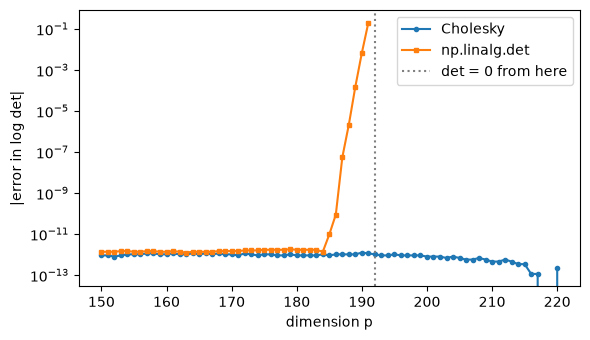

In [15]:
def ar1(p, rho):
    i = np.arange(p)
    return rho ** np.abs(i[:, None] - i[None, :])

rho = 0.99
ps = np.arange(150, 221)
err_chol, err_naive = [], []
for q in ps:
    S = ar1(q, rho)
    exact = (q - 1) * np.log(1 - rho ** 2)
    # YOUR CODE HERE
    L = sl.cholesky(S, lower=True)  # lower triangular Cholesky factor of this covariance
    diag_L = np.diag(L)  # positive diagonal entries l_jj of the factor
    log_diag_L = np.log(diag_L)  # logarithms avoid forming a tiny determinant
    ld_chol = 2 * np.sum(log_diag_L)  # log det S = 2 * sum(log l_jj), the stable log-determinant

    # This experiment deliberately pushes det beyond its floating-point range.
    with np.errstate(divide="ignore", over="ignore", invalid="ignore"):
        det_S = np.linalg.det(S)  # direct determinant; may round to zero
        ld_naive = np.log(det_S)  # keep negative infinity when det is zero
    err_chol.append(abs(ld_chol - exact))
    err_naive.append(abs(ld_naive - exact))

err_naive = np.array(err_naive)
first_bad = ps[np.argmax(err_naive > 1e-8)]
first_inf = ps[np.argmax(~np.isfinite(err_naive))]
print("naive log det first off by > 1e-8 at p =", first_bad, "; first infinite at p =", first_inf)
plt.figure(figsize=(6, 3.5))
plt.semilogy(ps, err_chol, "o-", ms=3, label="Cholesky")
plt.semilogy(ps, np.where(np.isfinite(err_naive), err_naive, np.nan), "s-", ms=3, label="np.linalg.det")
plt.axvline(first_inf, color="grey", ls=":", label="det = 0 from here")
plt.xlabel("dimension p"); plt.ylabel("|error in log det|"); plt.legend(); plt.tight_layout(); plt.show()

**Your answer.** Using $\det\Sigma = 0.0199^{p-1}$: the determinant drops below the smallest normal double ($2^{-1022}$) at $p = 182$, so it starts losing digits there, and below half the smallest subnormal double ($2^{-1075}$) at $p = 192$, where it rounds to zero.

The naive log-determinant first exceeds an error of $10^{-8}$ at $p = 187$ and becomes $-\infty$ at $p = 192$, where `det` returns exactly 0 although the matrix is still positive definite. Between 182 and 191 the determinant is subnormal and loses digits gradually: the error grows to about 0.2 at $p = 191$. The Cholesky version stays accurate over the whole range, with error at most about 1 trillionth ($10^{-12}$), because it adds logarithms of the diagonal of $L$ and never forms the tiny determinant.

**(d)** Time both implementations of the log-density for $p = 200, 400, 800, 1600$, on the AR(1) matrix or any symmetric positive definite matrix you like. Explain the ratio from the flop counts: Cholesky costs about $p^3/3$, LU (inside `det`) about $2p^3/3$, and an explicit inverse about $2p^3$.

In [16]:
def best_time(f, *args, repeat=3):
    best = np.inf
    for _ in range(repeat):
        t0 = time.perf_counter(); f(*args); best = min(best, time.perf_counter() - t0)
    return best

for q in [200, 400, 800, 1600]:
    S = ar1(q, 0.5)
    x, m0 = np.ones(q), np.zeros(q)
    t_c, t_n = best_time(gauss_logpdf, x, m0, S), best_time(gauss_logpdf_naive, x, m0, S)
    print(f"p = {q:5d}: Cholesky {1e3*t_c:8.2f} ms, naive {1e3*t_n:8.2f} ms, ratio {t_n/t_c:4.1f}")

p =   200: Cholesky     0.09 ms, naive     0.40 ms, ratio  4.5
p =   400: Cholesky     0.29 ms, naive     1.89 ms, ratio  6.5


p =   800: Cholesky     1.38 ms, naive    11.83 ms, ratio  8.6


p =  1600: Cholesky     9.24 ms, naive    84.98 ms, ratio  9.2


**Your answer.** Cholesky is faster at every size, and the gap grows with $p$: the naive version is about 4 times slower at $p = 200$ and about 9 times slower at $p = 1600$ (timings above). The flop counts explain the trend: Cholesky costs about $p^3/3$ plus a $p^2$ triangular solve, while the naive version needs an LU for `det` (about $2p^3/3$) and an explicit inverse (about $2p^3$), together $8p^3/3$, so the predicted ratio is about 8. Small matrices do not reach it because fixed overheads matter more than flops there. Exact milliseconds differ between machines and runs.

---
## A3. Sampling

If $\mathbf{z}\sim\mathcal{N}(0,I)$ and $BB^\top=\Sigma$, then $\boldsymbol\mu + B\mathbf{z}\sim\mathcal{N}(\boldsymbol\mu,\Sigma)$, for **any** such $B$. The Cholesky factor is the cheapest choice.

**(a)** Implement `gauss_sample(mu, Sigma, N, rng)`, returning an $N\times p$ array of samples $\boldsymbol\mu + L\mathbf{z}$.

In [17]:
def gauss_sample(mu, Sigma, N, rng):
    # YOUR CODE HERE
    p = len(mu)  # dimension: number of features in each generated observation
    L = sl.cholesky(Sigma, lower=True)  # factor with L @ L.T = Sigma
    Z = rng.standard_normal((N, p))  # independent standard-normal draws z_i, stored as rows
    LZ = Z @ L.T  # row i is (L z_i)^T: zero-mean samples with covariance L @ L.T = Sigma
    samples = LZ + mu  # x_i = mu + L z_i, shift every observation to the desired mean
    return samples

**(b)** *Predict, then compute.* How should the error $\|\operatorname{Cov}_N - \Sigma\|_F$ of the sample covariance of $N$ samples shrink as $N$ grows? Measure it for $\Sigma$ = the breast cancer correlation matrix and $N = 10^2,\dots,10^5$. Plot it on log–log axes and fit the slope.

**Your prediction** *(write it before running the next cell)*:

The sample covariance should get closer to $\Sigma$ as $N$ grows. Each entry is an average of $N$ random products, so its random error shrinks like $1/\sqrt{N}$: four times more samples should roughly halve the error, and the log–log slope should be about $-0.5$. Individual points may still deviate because the samples are random.


fitted slope: -0.480


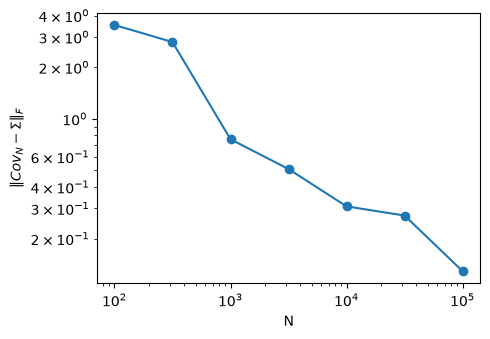

In [18]:
rng = np.random.default_rng(2)
Ns = np.array([10 ** k for k in [2, 2.5, 3, 3.5, 4, 4.5, 5]]).astype(int)
errs = []
for N in Ns:
    Y = gauss_sample(np.zeros(p), R, N, rng)
    errs.append(np.linalg.norm(sample_cov(Y) - R))
slope = np.polyfit(np.log(Ns), np.log(errs), 1)[0]
print(f"fitted slope: {slope:.3f}")
plt.figure(figsize=(5, 3.5)); plt.loglog(Ns, errs, "o-")
plt.xlabel("N"); plt.ylabel(r"$\|Cov_N - \Sigma\|_F$"); plt.tight_layout(); plt.show()

**Your answer.** The error falls from about 3.5 at $N = 100$ to about 0.13 at $N = 100{,}000$, and the fitted log–log slope is $-0.48$, close to the predicted $-0.5$. So the error shrinks roughly like $1/\sqrt{N}$. The points scatter around the line because the samples are random.

**(c)** Take the covariance of a random subsample of **20** rows of the standardised data `Xs` (seed below). It is a singular PSD matrix: why?
1. Show that `cholesky` fails on it.
2. Write `gauss_sample_psd(mu, Sigma, N, rng)`, which uses a factor from `eigh` instead: any $B$ with $BB^\top=\Sigma$. Set every eigenvalue below $10^{-12}\lambda_{\max}$ to zero. Why is it not enough to clip only the negative ones? (Hint: what is $\sqrt{10^{-16}}$?)
3. *Before checking, predict:* in which subspace do the samples lie? Verify by projecting the samples onto the (numerical) null space of $\Sigma$.

In [19]:
rng = np.random.default_rng(3)
S20 = sample_cov(Xs[rng.choice(n, 20, replace=False)])
try:
    sl.cholesky(S20, lower=True)
    print("Cholesky succeeded")
except np.linalg.LinAlgError as e:
    print("Cholesky failed:", e)

Cholesky failed: Internal potrf return info = [21] for slices [0].


**Your prediction** *(write it before running the next cell)*:

The samples should lie in the span of the eigenvectors with nonzero eigenvalue. 20 centred observations span at most 19 directions, even though there are 30 features, so the samples should have essentially zero projection onto the remaining null-space directions, up to rounding.


In [20]:
def gauss_sample_psd(mu, Sigma, N, rng):
    # YOUR CODE HERE
    p = len(mu)  # dimension: number of features in each sample
    lam, U = np.linalg.eigh(Sigma)  # eigenvalues lam and eigenvectors U: Sigma = U @ diag(lam) @ U.T
    cutoff = 1e-12 * lam[-1]  # relative threshold required by the assignment
    lam_kept = np.where(lam < cutoff, 0.0, lam)  # eigenvalues below the cutoff count as zero
    sqrt_lam = np.sqrt(lam_kept)  # standard deviation in each retained direction
    B = U * sqrt_lam  # B = U D^(1/2), columns scaled by sqrt of the kept eigenvalues: B @ B.T = Sigma
    Z = rng.standard_normal((N, p))  # independent standard-normal draws z_i, stored as rows
    BZ = Z @ B.T  # row i is (B z_i)^T: covariance only in the retained directions
    samples = BZ + mu  # x_i = mu + B z_i
    return samples

Y = gauss_sample_psd(np.zeros(p), S20, 5000, np.random.default_rng(4))
# YOUR CODE HERE
lam, U = np.linalg.eigh(S20)  # eigenvalues and eigenvectors of the singular covariance
cutoff = 1e-12 * lam[-1]  # same numerical-zero threshold as the sampler
null_mask = lam < cutoff  # directions with numerically zero variance
U_null = U[:, null_mask]  # columns form a basis for the numerical null space of S20
Y_null = Y @ U_null  # coordinates of the zero-mean samples along the null-space directions
max_projection = np.max(np.abs(Y_null))  # largest residual null-space coordinate
relative_projection = np.linalg.norm(Y_null) / np.linalg.norm(Y)  # residual relative to the sample size
print("retained directions:", np.count_nonzero(~null_mask))
print("null-space directions:", U_null.shape[1])
print(f"largest absolute null-space projection: {max_projection:.3e}")
print(f"relative null-space projection: {relative_projection:.3e}")
assert relative_projection < 1e-10

retained directions: 19
null-space directions: 11
largest absolute null-space projection: 2.397e-15
relative null-space projection: 2.088e-16


**Your answer.** The covariance is singular because 20 centred observations have rank at most 19, so at least 11 of the 30 eigenvalues are exactly zero: the matrix is positive semidefinite, not positive definite, and Cholesky fails on it, as the check shows.

The eigenvalue sampler keeps the 19 directions with nonzero variance and zeroes every eigenvalue below $10^{-12}\lambda_{\max}$. Clipping only the negative ones is not enough: a rounding-sized eigenvalue of $10^{-16}$ would give a standard deviation of $10^{-8}$ in a direction that should have none.

As predicted, the samples lie in the 19-dimensional range of $\Sigma$: their largest projection onto the 11 null-space directions is about 2 quadrillionths ($2 \times 10^{-15}$), which is rounding.

**(d)** What is the cost of one sample after the factorization, and of the factorization itself, in flops? Which dominates if you need $N = p$ samples?

**Your answer.** The Cholesky factorization is done once and costs about $p^3/3$ flops. One sample then costs one triangular matrix–vector product, about $p^2$ flops, plus $O(p)$ for drawing $z$ and adding $\mu$. For $N = p$ samples the sampling costs about $p^3$, three times the factorization, so sampling dominates even though both are cubic. Our code uses a dense product, about $2p^2$ per sample, which changes the constant but not the order. For the singular case the eigendecomposition is also $O(p^3)$, and its dense factor also costs about $2p^2$ per sample.

---
# Extensions — attempt **at most one** in the whole lab

End your extension with a paragraph headed **Finding**: one claim you can defend at the defence, supported by a number in this notebook.

## E1. Repairing a correlation matrix that is not PSD

*This topic was not lectured; the introduction below is all you need.*

Correlation matrices estimated from data with **missing values** are often computed *pairwise*: entry $(i,j)$ uses only the rows where both features $i$ and $j$ were observed. Each entry is then a valid correlation, but the matrix as a whole need not be PSD, because different entries come from different rows. A non-PSD "correlation" matrix breaks Cholesky, sampling and portfolio optimisation, so it must be repaired. The natural repair is the **nearest** correlation matrix:

$$\min\ \|C - R\|_F \quad\text{over symmetric } C\succeq 0 \text{ with } c_{ii}=1.$$

The feasible set is the intersection of two closed convex sets: the PSD cone, and the affine set of symmetric matrices with unit diagonal. Projection onto each set separately is easy; projection onto the intersection is not.

**(a)** Delete 10% of the entries of the breast cancer data at random (seed below), and compute the pairwise correlation matrix with `pandas.DataFrame.corr()`. Show that it is indefinite.

In [ ]:
rng = np.random.default_rng(0)
Xmiss = X.copy()
Xmiss[rng.random(X.shape) < 0.1] = np.nan
Rpw = pd.DataFrame(Xmiss).corr().values
print("most negative eigenvalue of the pairwise correlation:", np.linalg.eigvalsh(Rpw)[0])

**(b)** *Prove:* if $R = U\operatorname{diag}(\lambda)U^\top$, then the PSD matrix nearest to $R$ in the Frobenius norm is $U\operatorname{diag}(\max(\lambda,0))U^\top$.

*Hint.* The Frobenius norm is orthogonally invariant, so put $B = U^\top C U$ and compare $\|B - \operatorname{diag}(\lambda)\|_F^2$ with its diagonal part. What do you know about the diagonal of a PSD matrix?

**Your answer.** *Write it here.*

**(c)** Implement `proj_psd(A)` from (b) and `clip_rescale(R)`, which clips and then rescales to unit diagonal, $C \mapsto D^{-1/2}CD^{-1/2}$ with $D = \operatorname{diag}(C)$. Show numerically that the result is a correlation matrix but is **not** the nearest one. (You will have the nearest one in (d) to compare with.)

**(d)** Implement Higham's alternating projections (N. J. Higham, *Computing the nearest correlation matrix — a problem from finance*, IMA J. Numer. Anal. 22, 2002). Repeat:

$$R_k = Y_{k-1} - \Delta S_{k-1},\quad X_k = P_{\mathrm{PSD}}(R_k),\quad \Delta S_k = X_k - R_k,\quad Y_k = P_{\mathrm{unit}}(X_k),$$

starting from $Y_0 = R$, $\Delta S_0 = 0$. Here $P_{\mathrm{unit}}$ sets the diagonal to 1, and $\Delta S$ is **Dykstra's correction**. Stop when $\|Y_k - Y_{k-1}\|_F$ is below a tolerance.
- Compare the Frobenius distance to $R$ of the result of (c) and of Higham's method.
- Then omit Dykstra's correction (always $\Delta S = 0$) and run again. The iteration still returns a correlation matrix. Is it the nearest one? Compare the distances, and explain the geometric reason in terms of projections onto convex sets.

In [ ]:
def proj_psd(A):
    # YOUR CODE HERE
    raise NotImplementedError

def clip_rescale(R):
    # YOUR CODE HERE
    raise NotImplementedError

def nearest_corr(R, dykstra=True, tol=1e-12, maxit=10000):
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
def report(name, C):
    print(f"{name:22s} distance {np.linalg.norm(C - Rpw):.5f}, unit diagonal {np.allclose(np.diag(C), 1)}, "
          f"lambda_min {np.linalg.eigvalsh(C)[0]: .1e}")

report("clip and rescale", clip_rescale(Rpw))
C_h, its = nearest_corr(Rpw)
report(f"Higham ({its} iterations)", C_h)
C_nd, its_nd = nearest_corr(Rpw, dykstra=False)
report(f"no Dykstra ({its_nd} it.)", C_nd)
print("lower bound from (b), distance to the nearest PSD matrix:", np.linalg.norm(proj_psd(Rpw) - Rpw))

**Your answer.** *Write it here.*

## E2. Fisher's discriminant as a generalised eigenproblem

*Data:* `sklearn.datasets.load_wine`, 178 wines from 3 cultivars, 13 standardised chemical features.

Fisher's linear discriminant looks for directions $\mathbf{w}$ maximising $J(\mathbf{w}) = \dfrac{\mathbf{w}^\top S_B\mathbf{w}}{\mathbf{w}^\top S_W\mathbf{w}}$, where $S_W$ is the within-class scatter and $S_B$ the between-class scatter. Stationary points satisfy $S_B\mathbf{w} = \lambda S_W\mathbf{w}$ (frame `gen-eig`).

**(a)** Implement `scatter_matrices(X, y)`, returning $S_W = \frac1n\sum_k\sum_{i\in k}(\mathbf{x}_i-\bar{\mathbf{x}}_k)(\mathbf{x}_i-\bar{\mathbf{x}}_k)^\top$ and $S_B = \frac1n\sum_k n_k(\bar{\mathbf{x}}_k-\bar{\mathbf{x}})(\bar{\mathbf{x}}_k-\bar{\mathbf{x}})^\top$. *Before computing, predict* the rank of $S_B$; then confirm it.

**Your prediction** *(write it before running the next cell)*:

In [ ]:
Xw, yw = load_wine(return_X_y=True)
Xw = (Xw - Xw.mean(axis=0)) / Xw.std(axis=0)

def scatter_matrices(X, y):
    # YOUR CODE HERE
    raise NotImplementedError

SW, SB = scatter_matrices(Xw, yw)
print("rank S_B =", np.linalg.matrix_rank(SB), "; cond S_W =", round(np.linalg.cond(SW), 1))

**Your answer.** *Write it here.*

**(b)** Solve $S_B\mathbf{w} = \lambda S_W\mathbf{w}$ in two ways: with `scipy.linalg.eigh(SB, SW)`, and with `np.linalg.eig(np.linalg.solve(SW, SB))`.
- Compare the eigenvalues.
- Check which set of eigenvectors satisfies $V^\top S_WV = I$.
- Explain why the first route returns real eigenvalues by construction and the second does not.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

**Your answer.** *Write it here.*

**(c)** Project the data onto the two leading directions from `eigh` and plot it, coloured by cultivar.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

**(d)** Append a 14th feature that is an almost exact copy of the first, `Xw[:, 0] + eps * noise`, for `eps` $= 10^{-2}, 10^{-4}, \dots, 10^{-10}$ (noise fixed below). Track $\operatorname{cond}(S_W)$ and the two leading eigenvalues from both routes. At what `eps` do the routes part company, and which one do you trust? What would you do in practice?

**Your prediction** *(write it before running the next cell)*:

In [ ]:
noise = np.random.default_rng(5).standard_normal(len(Xw))
for eps in [1e-2, 1e-4, 1e-6, 1e-8, 1e-10]:
    Xa = np.column_stack([Xw, Xw[:, 0] + eps * noise])
    SWa, SBa = scatter_matrices(Xa, yw)
    # YOUR CODE HERE
    raise NotImplementedError
    print(f"eps {eps:.0e}: cond(S_W) {np.linalg.cond(SWa):.1e} | eigh {top_eigh} | eig {top_eig}")

**Your answer.** *Write it here.*

---
**Before you submit:** run `Kernel → Restart & Run All`, check that every written answer is filled in, and make sure your extension (if any) ends with a **Finding**.